# Recursive prototyping — end-to-end demo

The pipeline of *"Recursive prototyping for computational behavioral analysis from egocentric
videos"* (Perochon & Oudre), run on synthetic data. It turns per-window video embeddings into
one symbolic sequence per participant:

1. **Prototyping** — cosine k-means on a residual set, repeated over rounds; a person
   accepts or rejects each cluster from a visual probe image, and the accepted centroids are
   consolidated into a vocabulary of prototypes.
2. **Segmentation** — kernel change-point detection per participant, with one penalty
   calibrated across the cohort.
3. **Symbolization** — nearest-centroid assignment, a background filter, and a majority
   vote per segment.

Two stand-ins make the notebook self-contained: synthetic embeddings (participants revisit a
shared set of action clusters in contiguous runs, separated by background noise, with oracle
labels) and a scripted annotator in place of the interactive widget. Everything is seeded;
files are written to `outputs/demo_notebook/`.

## 1. Setup and synthetic data

A small configuration: 3 participants, 3 shared action clusters, 32-d embeddings, 60–100
windows each. About half of the windows overall are background noise (29–60 % per participant).

In [1]:
import itertools
import json
import time
from pathlib import Path

import numpy as np

from recursive_prototyping.config.schema import (
    PrototypingConfig,
    SegmentationConfig,
    SymbolizationConfig,
)
from recursive_prototyping.pipeline import (
    pooled_prototype_thresholds,
    run_full_pipeline,
)
from recursive_prototyping.segmentation.penalty import DEFAULT_HOP_SECONDS
from recursive_prototyping.prototyping.annotation_widget import fake_annotate
from recursive_prototyping.prototyping.refinement import (
    PooledFrameSourceAdapter,
    run_generative_step,
)
from recursive_prototyping.prototyping.vpm import (
    compute_cluster_stats,
    render_probe_image,
    sample_probe_indices,
)
from recursive_prototyping.synthetic.frames import SyntheticFrameSource
from recursive_prototyping.synthetic.generator import (
    SyntheticDatasetConfig,
    generate_synthetic_embeddings,
)
from recursive_prototyping.viz import (
    plot_prototype_gram,
    plot_prototype_radii,
    plot_similarity_matrix,
    plot_symbolic_timeline,
    plot_temperature_ablation,
)

# vpm.py forces the headless Agg backend at import time (it renders probe images
# straight to PNG); switch this notebook back to inline display AFTER those imports.
%matplotlib inline
import matplotlib.pyplot as plt

# Resolve the repo root robustly (nbconvert executes with cwd = notebooks/).
_cwd = Path.cwd().resolve()
REPO_ROOT = next(
    p for p in (_cwd, *_cwd.parents) if (p / "src" / "recursive_prototyping").exists()
)
OUT_DIR = REPO_ROOT / "outputs" / "demo_notebook"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"file outputs -> {OUT_DIR.relative_to(REPO_ROOT)}/")


file outputs -> outputs/demo_notebook/


In [2]:
SEED = 47

synth_config = SyntheticDatasetConfig(
    n_participants=3,
    n_action_clusters=3,
    embedding_dim=32,  # tiny stand-in for the paper's D=1408
    min_windows=60,
    max_windows=100,
    seed=SEED,
)
participants = generate_synthetic_embeddings(synth_config)
embeddings = {pid: p.embeddings for pid, p in participants.items()}

for pid, p in participants.items():
    print(
        f"{pid}: {len(p.embeddings)} windows, "
        f"{len(p.oracle_cpts) - 1} oracle segments "
        f"({len(p.oracle_cpts) - 2} interior change points), "
        f"{(p.oracle_cluster_ids == -1).mean():.0%} background windows"
    )


synth_000: 71 windows, 3 oracle segments (2 interior change points), 59% background windows
synth_001: 63 windows, 4 oracle segments (3 interior change points), 60% background windows
synth_002: 97 windows, 5 oracle segments (4 interior change points), 29% background windows


## 2. Prototyping: the visual probe image

Each round clusters the remaining ("residual") windows and asks the annotator to label every
cluster from a **visual probe image**: its *nearest* members next to its *furthest* ones, drawn from
as many participants as possible. The labels are:

- `task-definitive` / `exo-definitive` — the centroid is **accepted**; only the cluster's
  weakly assigned members (far from the centroid) return to the residual;
- `task-ambiguous` / `exo-ambiguous` — rejected; **all** its members return to the residual;
- `noise` — discarded.

The cell below runs round 1's clustering and renders one probe image. On synthetic data the
"frames" are placeholders: one solid color per oracle action cluster, gray speckle for
background. (Faiss warns that the dataset is small for 12 centroids; that is expected here.)

WARNING clustering 231 points to 12 centroids: please provide at least 468 training points


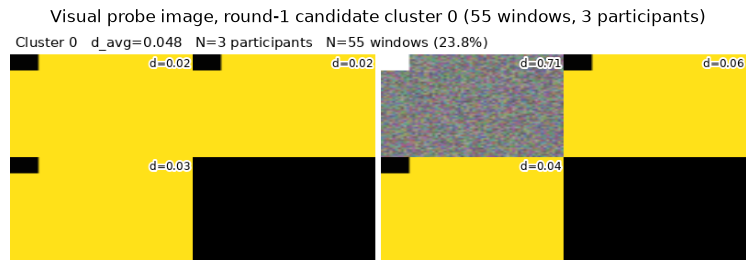

In [3]:
loop_config = PrototypingConfig(
    n_clusters_per_round=12,  # paper: C=100; scaled to the 231 pooled synthetic windows
    n_rounds=2,               # paper: P=8
    faiss_niter=50,
    faiss_nredo=1,
    n_probe_neighbors=6,      # paper: 30 nearest + 30 furthest
    n_probe_participants_target=3,
    probe_image_ncols=5,
)

# Pool the participants into one training matrix, keeping (participant, local window)
# bookkeeping so probe frames can be traced back to their source sequence.
X_pooled = np.concatenate([embeddings[pid] for pid in embeddings], axis=0)
pooled_pids = np.concatenate([np.full(len(embeddings[pid]), pid) for pid in embeddings])
pooled_local = np.concatenate([np.arange(len(embeddings[pid])) for pid in embeddings])

centroids, labels, distances = run_generative_step(X_pooled, loop_config)
cluster_id = int(np.bincount(labels).argmax())  # display the most populated candidate

nearest = sample_probe_indices(
    labels, distances, pooled_pids, cluster_id,
    n_neighbors=loop_config.n_probe_neighbors, side="nearest",
    max_participants=loop_config.n_probe_participants_target,
)
furthest = sample_probe_indices(
    labels, distances, pooled_pids, cluster_id,
    n_neighbors=loop_config.n_probe_neighbors, side="furthest",
    max_participants=loop_config.n_probe_participants_target,
)
stats = compute_cluster_stats(cluster_id, labels, distances, pooled_pids)

# Probe rendering needs participant-LOCAL window indices; the adapter translates the
# pooled row index back before it reaches the frame source.
frame_source = PooledFrameSourceAdapter(pooled_local, SyntheticFrameSource(participants))
probe_path = render_probe_image(
    cluster_id, nearest, furthest, stats, frame_source,
    OUT_DIR / "vpm_taste" / f"round_1_cluster_{cluster_id}.png",
    ncols=loop_config.probe_image_ncols,
)

fig, ax = plt.subplots(figsize=(9.5, 7))
ax.imshow(plt.imread(probe_path))
ax.axis("off")
ax.set_title(
    f"Visual probe image, round-1 candidate cluster {cluster_id} "
    f"({stats.n_embeddings} windows, {stats.n_participants} participants)"
)
plt.show()


## 3. Run the full pipeline

`run_full_pipeline` runs the three steps and writes every artifact. The scripted annotator
cycles `task-definitive` / `exo-definitive` / `task-ambiguous` over each round's clusters.

In [4]:
label_cycle = itertools.cycle(["task-definitive", "exo-definitive", "task-ambiguous"])

def scripted_annotator(image_paths, categories):
    # Deterministic stand-in for the human annotator: fake_annotate applies the
    # rule to each probe image path in order (re-run the notebook top-to-bottom, not
    # this cell alone, so the cycle starts fresh).
    return fake_annotate(image_paths, lambda _path: next(label_cycle))

t0 = time.perf_counter()
result = run_full_pipeline(
    embeddings,
    SyntheticFrameSource(participants),
    scripted_annotator,
    loop_config,
    SegmentationConfig(),  # stock defaults, incl. gamma_temperature=1.0
    SymbolizationConfig(),  # defaults: background_n_sigma=1.0, min_segment_length=4
    OUT_DIR,
    annotator_id="demo-notebook",
)
elapsed = time.perf_counter() - t0

G = result.vocabulary.shape[0]
print(f"pipeline finished in {elapsed:.1f} s")
print(f"vocabulary: G={G} prototypes, dim={result.vocabulary.shape[1]}")
for g, cluster_type in enumerate(result.vocabulary_cluster_types):
    print(f"  prototype {g}: {cluster_type}")


WARNING clustering 231 points to 12 centroids: please provide at least 468 training points


WARNING clustering 132 points to 12 centroids: please provide at least 468 training points


pipeline finished in 1.5 s
vocabulary: G=8 prototypes, dim=32
  prototype 0: exo-definitive
  prototype 1: exo-definitive
  prototype 2: task-definitive
  prototype 3: task-definitive
  prototype 4: exo-definitive
  prototype 5: task-definitive
  prototype 6: task-definitive
  prototype 7: exo-definitive


In [5]:
with result.artifact_paths["calibration_summary"].open() as f:
    calibration = json.load(f)

print(
    f"pooled slope-heuristic fit: slope={calibration['slope']:.3e}, "
    f"R^2={calibration['r_squared']:.3f}"
)
for pid, entry in calibration["participants"].items():
    print(
        f"  {pid}: penalty={entry['penalty']:.3f}, gamma={entry['gamma']:.3f}, "
        f"n_windows={entry['n_windows']}"
    )

print("\nartifacts written by the pipeline:")
for name, path in result.artifact_paths.items():
    print(f"  {name}: {path.relative_to(REPO_ROOT)}")


pooled slope-heuristic fit: slope=-3.544e-03, R^2=0.994
  synth_000: penalty=0.503, gamma=0.312, n_windows=71
  synth_001: penalty=0.447, gamma=0.266, n_windows=63
  synth_002: penalty=0.688, gamma=0.279, n_windows=97

artifacts written by the pipeline:
  refinement_state: outputs/demo_notebook/refinement
  vocabulary: outputs/demo_notebook/vocabulary.npy
  accepted_centroids: outputs/demo_notebook/accepted_centroids.npy
  centroid_to_prototype: outputs/demo_notebook/centroid_to_prototype.npy
  symbols: outputs/demo_notebook/symbols.npz
  calibration_summary: outputs/demo_notebook/calibration_summary.json
  prototyping_config: outputs/demo_notebook/prototyping_config.json
  segmentation_config: outputs/demo_notebook/segmentation_config.json
  symbolization_config: outputs/demo_notebook/symbolization_config.json


## 4. Segmentation

Change points are recovered from each participant's embeddings alone. The printout compares
them with the oracle boundaries.

interior change points, recovered vs oracle:
  synth_000: 3 recovered [9, 25, 54] vs 2 oracle [25, 54]
  synth_001: 4 recovered [25, 30, 38, 46] vs 3 oracle [30, 38, 46]
  synth_002: 4 recovered [20, 53, 58, 94] vs 4 oracle [20, 53, 58, 94]


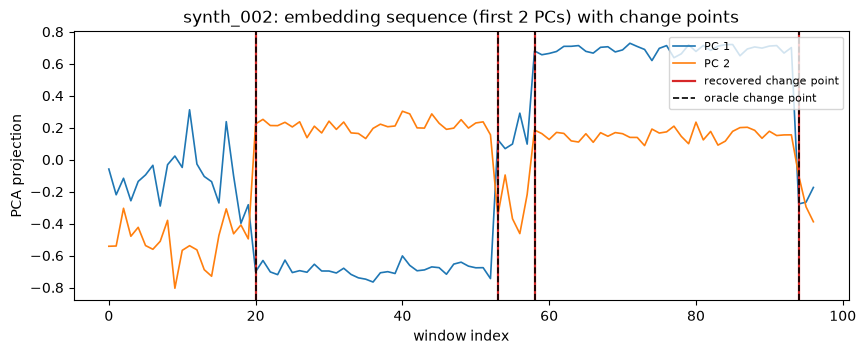

In [6]:
print("interior change points, recovered vs oracle:")
for pid in embeddings:
    recovered = result.participants[pid].segmentation_cpts
    oracle = participants[pid].oracle_cpts
    print(
        f"  {pid}: {len(recovered) - 2} recovered {recovered[1:-1].tolist()} "
        f"vs {len(oracle) - 2} oracle {oracle[1:-1].tolist()}"
    )

pid = "synth_002"
X = embeddings[pid]
X_centered = X - X.mean(axis=0)
_, _, Vt = np.linalg.svd(X_centered, full_matrices=False)
pcs = X_centered @ Vt[:2].T  # first two PCA components, [T, 2]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(pcs[:, 0], lw=1.2, label="PC 1")
ax.plot(pcs[:, 1], lw=1.2, label="PC 2")
for i, t in enumerate(result.participants[pid].segmentation_cpts[1:-1]):
    ax.axvline(t, color="tab:red", lw=1.6,
               label="recovered change point" if i == 0 else None)
for i, t in enumerate(participants[pid].oracle_cpts[1:-1]):
    ax.axvline(t, color="black", ls="--", lw=1.2,
               label="oracle change point" if i == 0 else None)
ax.set_xlabel("window index")
ax.set_ylabel("PCA projection")
ax.set_title(f"{pid}: embedding sequence (first 2 PCs) with change points")
ax.legend(loc="upper right", fontsize=8)
plt.show()


In the self-similarity matrix, a change point should sit at the corner of a diagonal block.
Cyan lines are the recovered boundaries.

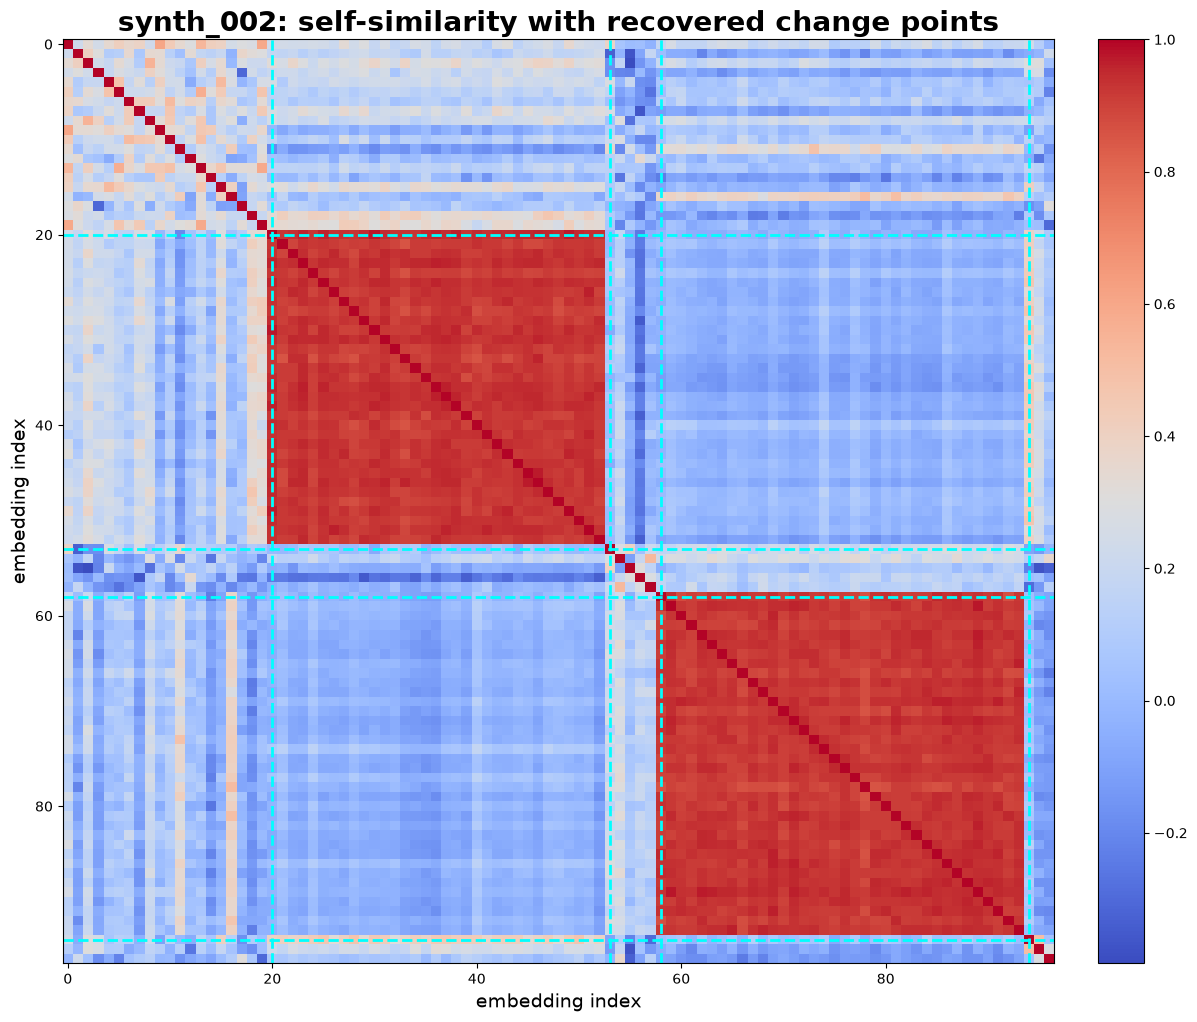

In [7]:
pid = "synth_002"          # the participant whose oracle is recovered verbatim
plot_similarity_matrix(
    embeddings[pid],
    result.participants[pid].segmentation_cpts,
    title=f"{pid}: self-similarity with recovered change points",
)
plt.show()


### Sensitivity to the kernel temperature

The RBF bandwidth is set per participant by the median heuristic,
`gamma = 1 / (2 * temperature * sigma^2)`. Raising the temperature widens the kernel; when it
is too wide every kernel value approaches 1 and the block structure disappears.

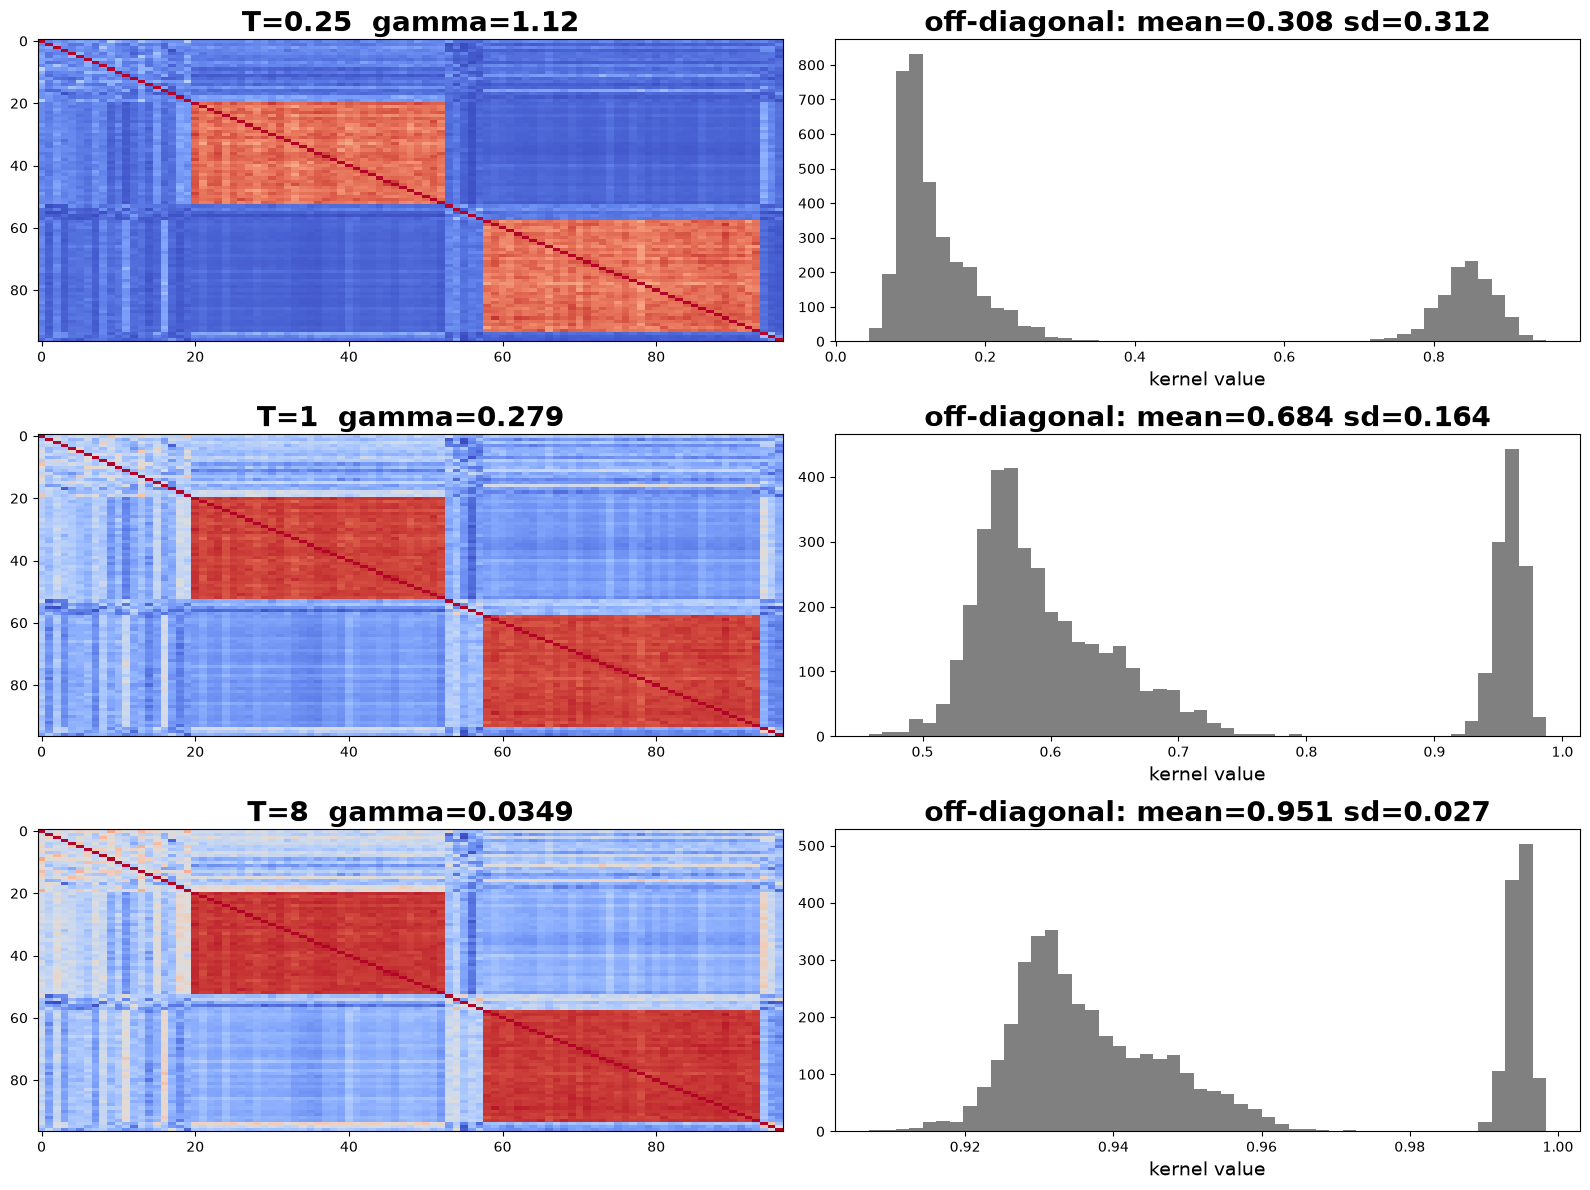

In [8]:
# The panel builds a dense T x T kernel per temperature, so on real-scale sequences
# (T ~ 5000) pass `window=` to restrict it. These synthetic participants are only
# 60-100 windows long, so the whole sequence fits.
plot_temperature_ablation(embeddings["synth_002"], temperatures=(0.25, 1.0, 8.0))
plt.tight_layout()
plt.show()


## 5. Symbolization

Each window is assigned to its nearest accepted centroid and takes that centroid's prototype.
Windows further from their centroid than their prototype's radius (mean + one standard
deviation of the assignment distances, pooled over the cohort) become background, printed as
`bg`. Each segment then takes the majority symbol of its central half.

With about half of the windows being background, the radius sits at the scale of the background
distances on this dataset, so some background segments keep a prototype symbol.

The timeline compares oracle action ids with the recovered per-window symbols. The two rows
use different alphabets, so compare the run structure and its boundaries, not the colors.

In [9]:
for pid in embeddings:
    res = result.participants[pid]
    symbol_string = " ".join("bg" if s == -1 else str(int(s)) for s in res.symbols)
    print(f"{pid}: [{symbol_string}]")
    print(
        f"  segmentation cpts ({len(res.segmentation_cpts)} entries) -> final cpts "
        f"after short-segment merge ({len(res.cpts)} entries): {res.cpts.tolist()}"
    )


synth_000: [5 5 6 4]
  segmentation cpts (5 entries) -> final cpts after short-segment merge (5 entries): [0, 9, 25, 54, 71]
synth_001: [3 3 6 2 bg]
  segmentation cpts (6 entries) -> final cpts after short-segment merge (6 entries): [0, 25, 30, 38, 46, 63]
synth_002: [1 0 bg 6 bg]
  segmentation cpts (6 entries) -> final cpts after short-segment merge (6 entries): [0, 20, 53, 58, 94, 97]


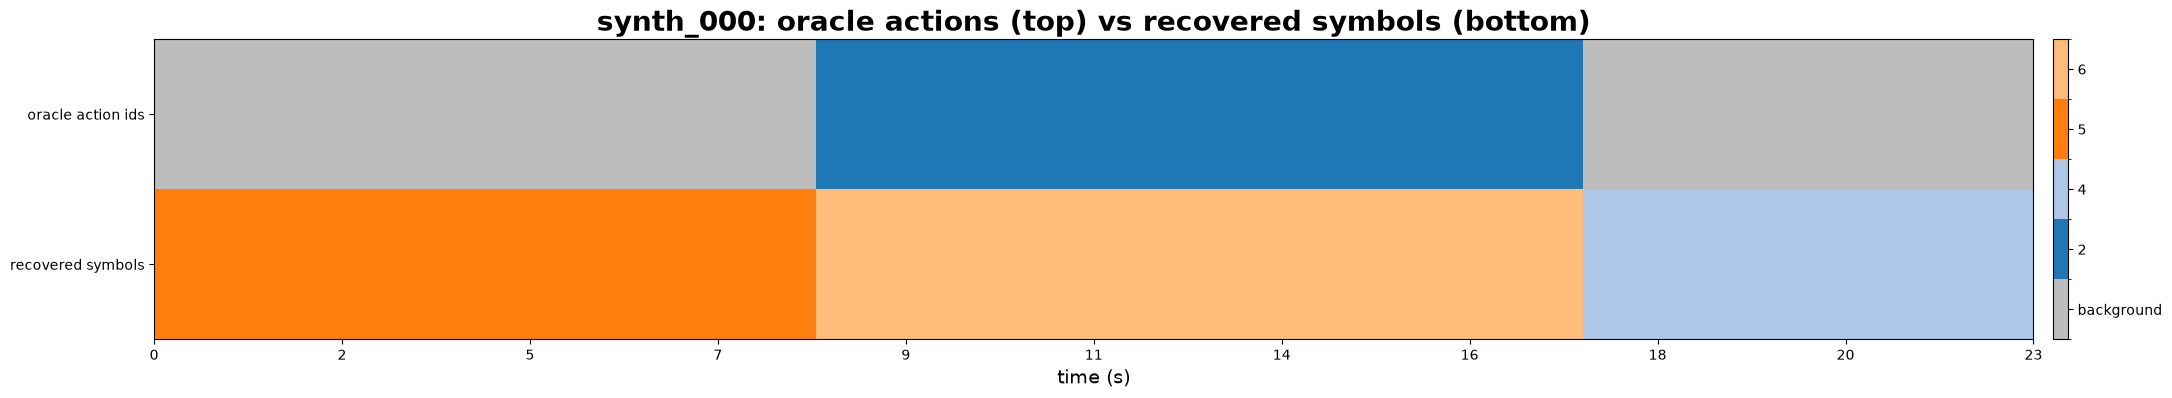

In [10]:
pid = "synth_000"

# Both rows share one colormap, so read them within-row: the oracle uses 3 action
# ids, the learned vocabulary however many prototypes consolidation kept. What should
# line up is the run structure and where it breaks, not the colors.
ax = plot_symbolic_timeline(
    np.vstack([participants[pid].oracle_cluster_ids,
               result.participants[pid].window_symbols]),
    hop_seconds=DEFAULT_HOP_SECONDS,
    title=f"{pid}: oracle actions (top) vs recovered symbols (bottom)",
)
ax.set_yticklabels(["oracle action ids", "recovered symbols"])
plt.show()


### The vocabulary

The Gram matrix of the prototypes should show off-diagonal similarities well below 1; the
second plot shows the per-prototype background radii the pipeline applied.

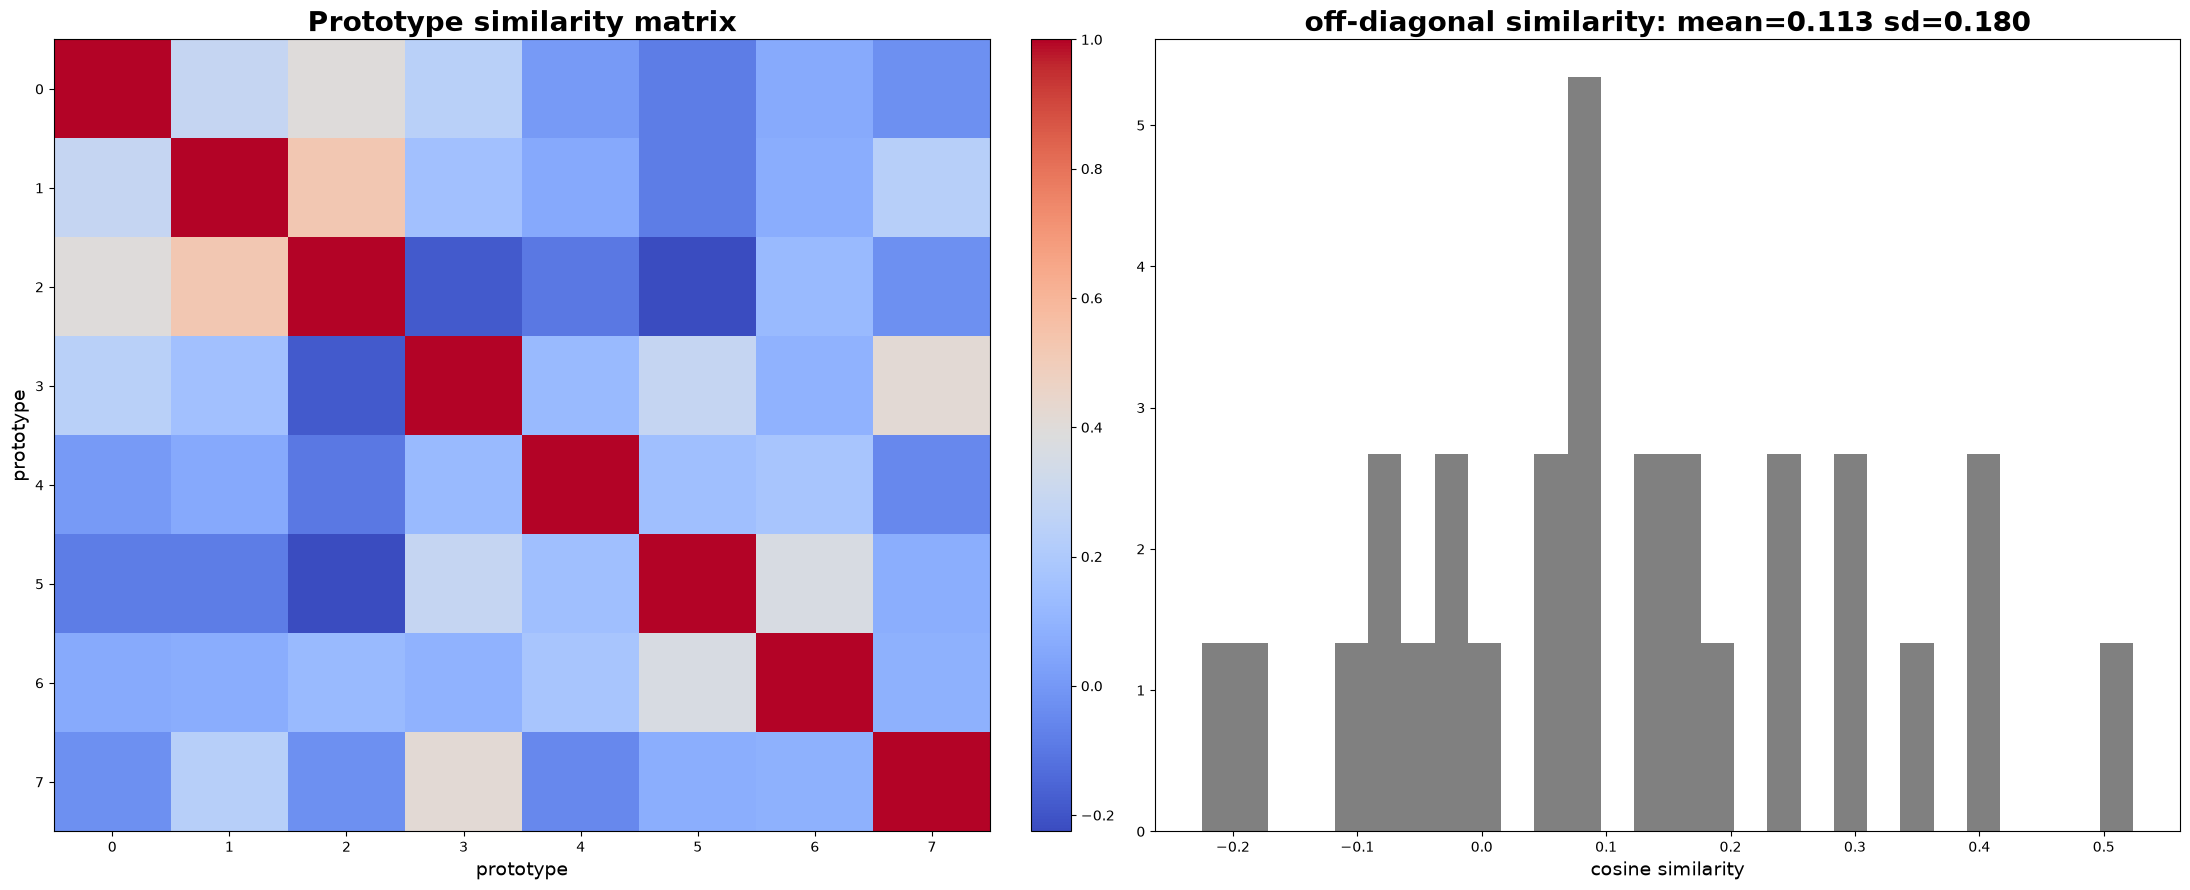

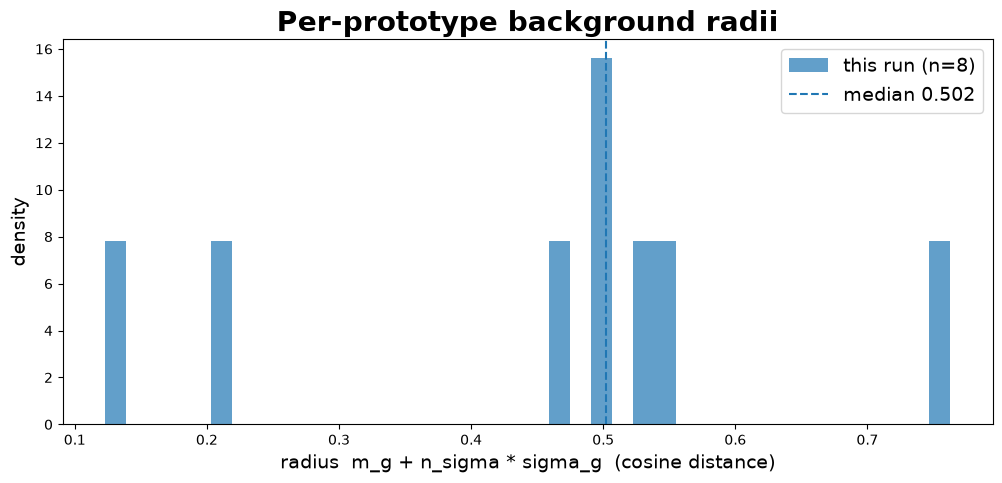

In [11]:
plot_prototype_gram(result.vocabulary)
plt.tight_layout()
plt.show()

thresholds = pooled_prototype_thresholds(
    embeddings, result.accepted_centroids, SymbolizationConfig(), result.centroid_to_prototype
)
plot_prototype_radii(thresholds)
plt.show()


## 6. Where to go next

- `docs/METHOD.md` states the method as implemented and the choices the paper leaves open.
- The README section *Running on your own data* lists what the pipeline needs from you.
- The README section *Annotating with a person in the loop* replaces the scripted annotator
  used here by the interactive widget, round by round.
- Everything written here is under `outputs/demo_notebook/`.